# IN4080: obligatory assignment 2 (Autumn 2026)

Mandatory assignment 2 consists of three parts. In Part 1, you will experiment with a greedy sequence labeling model and investigate the impact of different feature types on **part-of-speech tagging** performance (9 points + 2 optional bonus points). In Part 2, you will evaluate the best model on a different task, **named entity recognition** (5 points). In Part 3, you will return to the **text classification task** and implement a simple feed-forward neural network for it (6 points).

You should answer all three parts. You are required to get at least 12/20 points to pass. The most important is that you try to answer each question (possibly with some mistakes), to help you gain a better and more concrete understanding of the topics covered during the lectures. In the first part, there are also bonus questions for those of you who would like to deepen their understanding of the topics covered by this assignment.

- We assume that you have read and are familiar with IFI’s requirements and guidelines for mandatory assignments, see [here](https://www.uio.no/english/studies/examinations/compulsory-activities/mn-ifi-mandatory.html) and [here](https://www.uio.no/english/studies/examinations/compulsory-activities/mn-ifi-guidelines.html).
- This is an individual assignment. You should not deliver joint submissions.
- You may redeliver in Devilry before the deadline (__Friday, October 2 at 23:59__), but include all files in the last delivery.
- Only the last delivery will be read! If you deliver more than one file, put them into a zip-archive. You don't have to include in your delivery the files already provided for this assignment.
- Name your submission _your\_username\_in4080\_mandatory\_2_
- You can work on this assignment either on the IFI machines or on your own computer.

*The preferred format for the assignment is a completed version of this Jupyter notebook*, containing both your code and explanations about the steps you followed. We want to stress that simply submitting code is __not__ by itself sufficient to complete the assignment - we expect the notebook to also contain explanations of what you have implemented, along with motivations for the choices you made along the way. Preferably use whole sentences, and mathematical formulas if necessary. Explaining in your own words (using concepts we have covered through in the lectures) what you have done and reflecting on your solution is an important part of the learning process - take it seriously!

Regarding the use of LLMs (ChatGPT or similar): you are allowed to use them as 'sparring partner', for instance to clarify something you have not understood. However, you are __not__ allowed to use them to generate solutions (either in part or in full) to the assignment tasks. If you are using code editors such as VS Code, you should make sure that code completion plugins such as Copilot are disabled when working on the assignment.

In this assignment, we'll use the following Python modules: `scikit-learn, pyconll, matplotlib, sentence_transformers`. Make sure you have installed them.

In [ ]:
# if you use a virtual environment, you can install the modules like this
%pip install scikit-learn pyconll matplotlib sentence_transformers

## Before starting to read my code and results, I tried to provide informative comments for the code, and for each part that was needed, I wrote a Markdown like the following.

--------------------
### My explanation
You can find my "blablabla" here :)

--------------

## Thanks for your attention

## Part 1 – Greedy logistic regression taggers and feature engineering

In the lecture, we have discussed Matthew Honnibal's proposal of a discriminative sequence labelling model with greedy decoding. He argued that an extended set of features is more helpful for tagging than exact (Viterbi) decoding. Therefore, we skip HMMs and the Viterbi algorithm here and focus on models based on logistic regression.

Scikit-learn doesn't contain implementations of sequence labeling models. Therefore, we provide you with some basic code. The code below defines a `GreedyTagger` with a `fit()` function for training and a `predict()` function for prediction/testing. By default, it uses a standard Scikit-learn logistic regression classifier under the hood, which takes a feature vector for a word (and its context) as input and provides the most likely class label as output.

Your task in this part will mainly consist in defining how a word (and its context) is converted to a feature vector.

In [1]:
import numpy as np
import sklearn
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction import DictVectorizer


class GreedyTagger:
    """
    Tagger based on logistic regression or any other classification algorithm supported by Scikit-Learn.
    """

    def __init__(
        self,
        feature_function,
        classifier=LogisticRegression(),
    ):
        """
        Creates a GreedyTagger object.

        Args:
            feature_function: A function that transforms the input sequence and the index of the current word into a set of key-value pairs.
            classifier: A Scikit-Learn classifier instance.
        """
        self.features = feature_function
        self.classifier = classifier
        self.vectorizer = DictVectorizer()
        self.label_ids = {}  # mapping from labels to numeric label ids
        self.id_labels = {}  # mapping from numeric label ids to labels

    def fit(self, dataset_X, dataset_Y):
        """
        Trains the tagger. Creates a list of inputs (feature vectors of individual words) and a list of labels (numeric ids) and calls the `fit` function of the base classifier on these lists.

        Args:
            dataset_X: The input training data, formatted as a list of lists. Each list item represents a sentence and corresponds to a list of tokens.
            dataset_Y: The training data labels, formatted as a list of lists. Each list item represents a sentence and corresponds to a list of labels (e.g. POS-tags or BIO-tags).
        """
        flattened_dataset_X = []  # a flat list of training instances
        flattened_dataset_Y = []  # a flat list of label ids for the training instances
        for sentence_X, sentence_Y in zip(dataset_X, dataset_Y):
            # sentence_X is a list of words
            # sentence_Y is a list of labels, one for each word of the sentence
            history = []
            for i, (x, y) in enumerate(zip(sentence_X, sentence_Y)):
                feature_dict = self.features(sentence_X, i, history)
                flattened_dataset_X.append(feature_dict)
                if y not in self.label_ids:
                    self.label_ids[y] = len(self.label_ids)
                flattened_dataset_Y.append(self.label_ids[y])
                history.append(y)
        transformed_dataset_X = self.vectorizer.fit_transform(flattened_dataset_X)
        transformed_dataset_Y = np.array(flattened_dataset_Y)
        self.id_labels = {self.label_ids[label]: label for label in self.label_ids}
        self.classifier.fit(transformed_dataset_X, transformed_dataset_Y)
        return self

    def predict(self, dataset_X):
        """
        Predicts the labels for the input data, sentence by sentence.

        Args:
            dataset_X: The input training data, formatted as a list of lists. Each list item represents a sentence and corresponds to a list of tokens.

        Returns:
            list: The predicted labels, in the same format as dataset_X (list of lists).
        """
        predictions = []
        for sentence_X in dataset_X:
            flattened_sentence_X = []
            history = []
            for i, word in enumerate(sentence_X):
                feature_dict = self.features(sentence_X, i, history)
                flattened_sentence_X.append(feature_dict)
            transformed_sentence_X = self.vectorizer.transform(flattened_sentence_X)
            predicted_sentence_Y = self.classifier.predict(transformed_sentence_X)
            predicted_labels_Y = [self.id_labels[y] for y in predicted_sentence_Y]
            predictions.append(predicted_labels_Y)
        return predictions

When instantiating this class, you need to provide a so-called *feature function* that defines how the feature vector is created. In the provided implementation, this is done in two steps:
1. The feature function creates a feature dictionary. Each key of the dictionary defines a one-hot vector, and the value determines which value of the vector will be set to one. For example, the feature dictionary `{"curr_word": "love", "prev_word": "I", "next_word": "fish"}` defines three one-hot vectors, which together represent the word `love` in the sequence `I love fish`. The keys can be chosen freely.
2. The `DictVectorizer` class of Scikit-Learn will convert the feature dictionary to actual one-hot vectors and concatenate them into a single vector. This step is already taken care of in the `fit()` function.

A basic feature function that only uses the current word could look like this (we will use the parameter `history` later, but don't worry about it now):

In [22]:
def basic_features(sentence, i, history):
    features = {"curr_word": sentence[i]}
    return features

The `predict()` function only returns the predicted labels, it doesn't compare them to the ground truth. Here is another function that computes accuracy for the predictions of a dataset. However, the function is incomplete -- it only uses the first sentence of the dataset.

**Task 1.1** (1 point): Modify the function to take into account all sentences of the dataset. The easiest way to achieve this is to flatten a list of lists into a single list, so you'll only have to call the `accuracy_score` function once.

In [23]:
def tagging_accuracy(dataset_Y_true, dataset_Y_pred):
    ## CHANGE CODE HERE
    
    #Flatten the data
    flattend_dataset_Y_true = [tag for sent in dataset_Y_true for tag in sent]
    flattend_dataset_Y_pred = [tag for sent in dataset_Y_pred for tag in sent]
    acc = sklearn.metrics.accuracy_score(flattend_dataset_Y_true, flattend_dataset_Y_pred)
    return acc

Finally, we need some actual data to work with. We provide you with part-of-speech annotated data for Norwegian Bokmål taken from (https://universaldependencies.org/).

You can use our preprocessed `.conllu` files, which are saved as `.json` files


In [24]:
import json


def load_data_from_json(filename):
    with open(filename, "r", encoding="utf-8") as f:
        data = json.load(f)
    X, Y = [], []
    for sentence in data:
        X.append(sentence["sentence"])
        Y.append(sentence["labels"])
    return X, Y


train_data_x, train_data_y = load_data_from_json("no_bokmaal-ud-train.json")
valid_data_x, valid_data_y = load_data_from_json("no_bokmaal-ud-dev.json")
test_data_x, test_data_y = load_data_from_json("no_bokmaal-ud-test.json")

In any of the options, the data should look like this:

In [25]:
train_data_x[0], train_data_y[0]

(['Lam', 'og', 'piggvar', 'på', 'bryllupsmenyen'],
 ['NOUN', 'CCONJ', 'NOUN', 'ADP', 'NOUN'])

Now, we can put everything together. Let us train a tagger on the training data and evaluate it on the validation set.

**Task 1.2** (1 point): Write the corresponding code and output the accuracy (as a number between 0 and 1).

In [26]:
# First initilize an object from GreadyTagger class, then fit that with the correspanding data
gt = GreedyTagger(basic_features)
gt.fit(train_data_x, train_data_y)

/fp/homes01/u01/ec-armans/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [7]:
predicted_valid_data_y = gt.predict(valid_data_x)
tagging_accuracy(valid_data_y, predicted_valid_data_y)

0.8682669306277324

**Task 1.3** (1 point): The basic feature function only looks at the current word. Also add the previous word, the next word, and the word before the previous one. Make sure to handle edge cases at the beginning and at the end of the sentence. For example, the feature dictionary for the first word of `I love fish` could look as follows: `{"curr_word": "I", "prev_word": "<START>", "prev2_word": "<START>", "next_word": "love"}` (you should still not need the parameter `history` for this). Add one feature at a time, train a model, and record the accuracy. Describe which combination of features works best.

In [27]:
def context_features(sentence, i, history):
    features = {"curr_word": sentence[i]}

    # Put the <Start> for the tokens falling behind the token or word with index 0 or 1
    if i == 0:
        features["prev_word"] = "<Start>"
    else:
        features['prev_word'] = sentence[i-1]


    return features

In [28]:
gt = GreedyTagger(context_features)
gt.fit(train_data_x, train_data_y)
predicted_valid_data_y = gt.predict(valid_data_x)
tagging_accuracy(valid_data_y, predicted_valid_data_y)

/fp/homes01/u01/ec-armans/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.890758613104567

In [29]:
def context_features(sentence, i, history):
    features = {"curr_word": sentence[i]}
    
    # Put the <Start> for the tokens falling behind the token or word with index 0 or 1
    if i == 0:
        features["prev_word"] = "<Start>"
        features["prev2_word"] = "<Start>"

    elif i == 1:
        features["prev2_word"] = "<Start>"
        features['prev_word'] = sentence[i-1]

    else:
        features['prev_word'] = sentence[i-1]
        features['prev2_word'] = sentence[i-2]


    return features

In [30]:
gt = GreedyTagger(context_features)
gt.fit(train_data_x, train_data_y)
predicted_valid_data_y = gt.predict(valid_data_x)
tagging_accuracy(valid_data_y, predicted_valid_data_y)

/fp/homes01/u01/ec-armans/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8935631994280844

In [31]:
def context_features(sentence, i, history):
    features = {"curr_word": sentence[i]}

    if i == len(sentence) - 1:
        # Here <End> means the end of sentence
        features["next_word"] = '<End>'
    else:
        features["next_word"] = sentence[i+1]
    # Put the <Start> for the tokens falling behind the token or word with index 0 or 1
    if i == 0:
        features["prev_word"] = "<Start>"
        features["prev2_word"] = "<Start>"

    elif i == 1:
        features["prev2_word"] = "<Start>"
        features['prev_word'] = sentence[i-1]

    else:
        features['prev_word'] = sentence[i-1]
        features['prev2_word'] = sentence[i-2]


    return features

In [32]:
gt = GreedyTagger(context_features)
gt.fit(train_data_x, train_data_y)
predicted_valid_data_y = gt.predict(valid_data_x)
tagging_accuracy(valid_data_y, predicted_valid_data_y)

/fp/homes01/u01/ec-armans/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.919216915504963

--------------------
### My explanation

In each step, I added a new feature and kept the previous ones:

Just the **current token**: 86.82%

After adding **one previous token**: 89.07%

After adding **two previous tokens**: 89.35%

After adding the **next token**: 91.92%
 
--------------------

**Task 1.4** (1 point): Up to now, we are still using a unigram model, in the sense that no information about the *labels* at previous positions is incorporated. Let us change this now by adding so-called *transition features*. Add a key `prev_tag` to the feature function and fill it with the label of the previous position. You can use the `history` parameter for this. Write your new feature function below:

In [33]:
def transition_features(sentence, i, history):
    #Use the context features function to get the features and add the prev tag in this function
    features = context_features(sentence, i, history)
    if i ==0:
        features['prev_tag'] = '<Start>'
    else:
        features['prev_tag'] = history[i-1]
    return features

Before you start training the model with the transition features, have a closer look at the starter code provided at the beginning. You will notice that the `history` parameter is correctly filled in the `fit()` function, but that it always remains empty in the `predict()` function. With this setup, adding transition features will not have any impact on the accuracy. You will therefore have to implement an alternative prediction function that fixes this issue.

**Task 1.5** (2 points): Complete the `predict_with_history()` function below such that the history list is filled with the predicted label at each step. Instead of calling `self.classifier.predict()` once per sentence, you will have to call it for each word separately, because the feature vector for a given position can only be computed once the previous word has been labeled.

In [34]:
# I applied many changes here; to label the previous word, we should move the prediction inside the loop so that for each word, 
# the predicted label is appended to the history list.

def predict_with_history(self, dataset_X):
    predictions = []
    for sentence_X in dataset_X:
        predicted_labels_sentence_Y = []
        history = []
        for i, word in enumerate(sentence_X):
            feature_dict = self.features(sentence_X, i, history)
            # Vectorize the information related to one word
            transformed_sentence_X = self.vectorizer.transform([feature_dict,])
            # Predict the label of the corresponding word
            predicted_sentence_Y = self.classifier.predict(transformed_sentence_X)
            predicted_labels_Y = self.id_labels[predicted_sentence_Y[0]] 
            # Append it to the history
            history.append(predicted_labels_Y)
            predicted_labels_sentence_Y.append(predicted_labels_Y)

        predictions.append(predicted_labels_sentence_Y)

    return predictions


# attach the function to the GreedyTagger class
setattr(GreedyTagger, "predict_with_history", predict_with_history)

**Task 1.6** (1 point): Train a new tagger using the transition features and the `predict_with_history()` function. Do the transition features help? Note: The prediction will be significantly slower than before because of the modifications made above.

In [35]:
# First initilize an object from GreadyTagger class with the transition_features method
gt = GreedyTagger(transition_features)
gt.fit(train_data_x, train_data_y)

/fp/homes01/u01/ec-armans/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [36]:
predicted_valid_data_y = gt.predict_with_history(valid_data_x)
tagging_accuracy(valid_data_y, predicted_valid_data_y)

0.9175946547884187

--------------------
### My explanation

The results are interesting; using transition_features definitely helped our accuracy. As you can see in the previous cells, the plain predictor achieved 86.8% on the validation set, but the transitional one achieved 91.7%. However, just using context_features with all of the proposed features and without history gave us an even better result on the validation set: about 91.92%. Because using history increases the running time, it seems to me that just using context features may be more logical.


--------------------


**Task 1.7** (_optional, 2 extra points_): You may have noticed that there is a significant implementation difference between the `fit()` and `predict_with_history()` functions. During training, the `history` list is filled with the *gold* labels directly taken from the annotated training data. During prediction, the gold labels are not available, so we have to resort to the *predicted* labels. Could this approach lead to any problems? If so, how could it be improved?

--------------------
### My explanation

Yes, this could cause some problems:

1. In the training phase, we use the true labels as the previous tag. Since prev_tag is always correct during training, the model learns to rely heavily on it. In other words, the model is never exposed to its own mistakes during training.

2. In prediction, however, we use the predicted tag from each step as prev_tag. If a prediction is wrong, the error can snowball and corrupt the following labels, because the model has never seen an incorrect prev_tag during training. This is what makes the errors cascade.

**What could be an approach?**

During training, the model should be prepared for the fact that the history can contain mistakes. For example, we could deliberately change some of the tags in the history.

Another idea is to include, instead of only the previous tag, the probability of each tag in the feature vector. This way, the model could learn how much it should rely on the previous tags.

--------------------

**Task 1.8** (_optional, 2 extra points_): Take the currently best-performing feature function and add even more features to get an even better tagger. Some ideas:
- Extract suffixes and prefixes of $n$ characters ($1 \leq n \leq 4$) from the current, previous or next word.
- Is the current word a number?
- Is it capitalized?
- Does it contain capitals?
- Does it contain a hyphen? etc.

What is the best feature set you can come up with? Define various feature sets and select the best one based on validation set accuracy.
If you use sources for finding tips about good features (like articles, web pages, etc.) make references to the sources and explain what you got from them.

In [41]:
import re

# To check different situations, I implement different functions.
def get_suf_pre(features):
    words = ['curr_word', 'next_word', 'prev_word', 'prev2_word']
    sentinels = {'<Start>', '<end>'}
    # Add suffix and prefix for each words that we have in the features
    for word in words:
        token = features.get(word, "")
        if token in sentinels:
            continue
        token = token.lower()
        for i in range(1, min(len(token)+1, 5)):
            features[f'{word}_prefix{i}'] = token[:i]
            features[f'{word}_suffix{i}'] = token[-i:]

    return features

# Check whether the token is digit or word
def check_digit(current):
    return 'digit' if re.search(r'\d', current) else 'word'

# Check whether the first letter of the word is capitalized or not
def is_capitalized(current):
    return 'uppercase' if current and current[0].isupper() else 'lowercase'

# Check whether there is any capital letter in the word or not
def contain_capital(current):
    return 'capital' if any(c.isupper() for c in current) else 'small'


In [42]:
# Add suffix and prefix features to the context features.
def additive_features(sentence, i, history):
    #To follow DRY principle ( Don't repeat yourself :) ) I use the best feature function that's been implemented and add the requested features to it.
    features = context_features(sentence, i, history)
    features = get_suf_pre(features)

    return features

In [43]:
# Let's try to see this new feature function can bring in advantage for us or not:
gt = GreedyTagger(additive_features)
gt.fit(train_data_x, train_data_y)

/fp/homes01/u01/ec-armans/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [44]:
predicted_valid_data_y = gt.predict(valid_data_x)
tagging_accuracy(valid_data_y, predicted_valid_data_y)

0.9518271055019385

In [45]:
# Add digit status to the additive features
def additive_features(sentence, i, history):
    #To follow DRY principle ( Don't repeat yourself :) ) I use the best feature function that's been implemented and add the requested features to it.
    features = context_features(sentence, i, history)
    features = get_suf_pre(features)

    current_word = features.get('curr_word', '')

    features['digit_status'] = check_digit(current_word)

    return features

In [46]:
# Let's try to see this new feature function can bring in advantage for us or not:
gt = GreedyTagger(additive_features)
gt.fit(train_data_x, train_data_y)
predicted_valid_data_y = gt.predict(valid_data_x)
tagging_accuracy(valid_data_y, predicted_valid_data_y)

/fp/homes01/u01/ec-armans/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.951249690670626

In [47]:
# Add capitalization status to the additive features
def additive_features(sentence, i, history):
    #To follow DRY principle ( Don't repeat yourself :) ) I use the best feature function that's been implemented and add the requested features to it.
    features = context_features(sentence, i, history)
    features = get_suf_pre(features)

    current_word = features.get('curr_word', '')

    features['digit_status'] = check_digit(current_word)
    features['capitalization_status'] = is_capitalized(current_word)

    return features

In [48]:
# Let's try to see this new feature function can bring in advantage for us or not:
gt = GreedyTagger(additive_features)
gt.fit(train_data_x, train_data_y)
predicted_valid_data_y = gt.predict(valid_data_x)
tagging_accuracy(valid_data_y, predicted_valid_data_y)

/fp/homes01/u01/ec-armans/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.9594984739750887

In [49]:
# Add contains capital status to the additive features
def additive_features(sentence, i, history):
    #To follow DRY principle ( Don't repeat yourself :) ) I use the best feature function that's been implemented and add the requested features to it.
    features = context_features(sentence, i, history)
    features = get_suf_pre(features)

    current_word = features.get('curr_word', '')

    features['digit_status'] = check_digit(current_word)
    features['capitalization_status'] = is_capitalized(current_word)
    features['contains_capital'] = contain_capital(current_word)

    return features

In [50]:
# Let's try to see this new feature function can bring in advantage for us or not:
gt = GreedyTagger(additive_features)
gt.fit(train_data_x, train_data_y)
predicted_valid_data_y = gt.predict(valid_data_x)
tagging_accuracy(valid_data_y, predicted_valid_data_y)

/fp/homes01/u01/ec-armans/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.9591135307542138

--------------------
### My explanation

As you can see in the above results, adding the suggested features step by step mostly improved the accuracy; only the digit status (95.18 to 95.12) and the contains capital feature (95.95 to 95.91) decreased it slightly. The result on the validation set showed a significant improvement from 91.9 to 95.9.

--------------------

Up to now, we have been working on the development set. It is time now to evaluate your best-performing model on the held-out test set.

**Task 1.9** (2 points): First, compute the *test set accuracy* of your best model. However, the accuracy only gives us a high-level overview of the performance of a tagger, but we may be interested in finding out more details about where the tagger makes the mistakes. The universal tagset is reasonably small, so we can produce a *confusion matrix*. Take a look at https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html and generate a confusion matrix for the results. Which pairs of tags are most easily confounded? You can find the documentation of the tagset in the following link: https://universaldependencies.org/u/pos/index.html

In [51]:
gt = GreedyTagger(additive_features)
gt.fit(train_data_x, train_data_y)

/fp/homes01/u01/ec-armans/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [52]:
predicted_test_data_y = gt.predict(test_data_x)
tagging_accuracy(test_data_y, predicted_test_data_y)

0.9540479209771073

--------------------
### My explanation

The accuracy on test data is soo goood :] it's about 95.40 .

In the following, You can see the confusion matrix:
Based on the confusion matrix, the most easily confounded tag pairs are:

* True tag **X** misclassified as **NOUN** (0.25 rate).


* True tag **INTJ** misclassified as **NOUN** (0.14 rate).


* True tag **X** misclassified as **VERB** (0.10 rate).


* True tag **X** misclassified as **ADP** (0.10 rate).


I think the result makes sense, because the confusion mostly happened around **X**, which is the other tags. The ambiguity of this tag could cause some confounding.

It worth to mention true posetive rate on **INTJ** is not as good as the others: about (0.73 rate)



--------------------

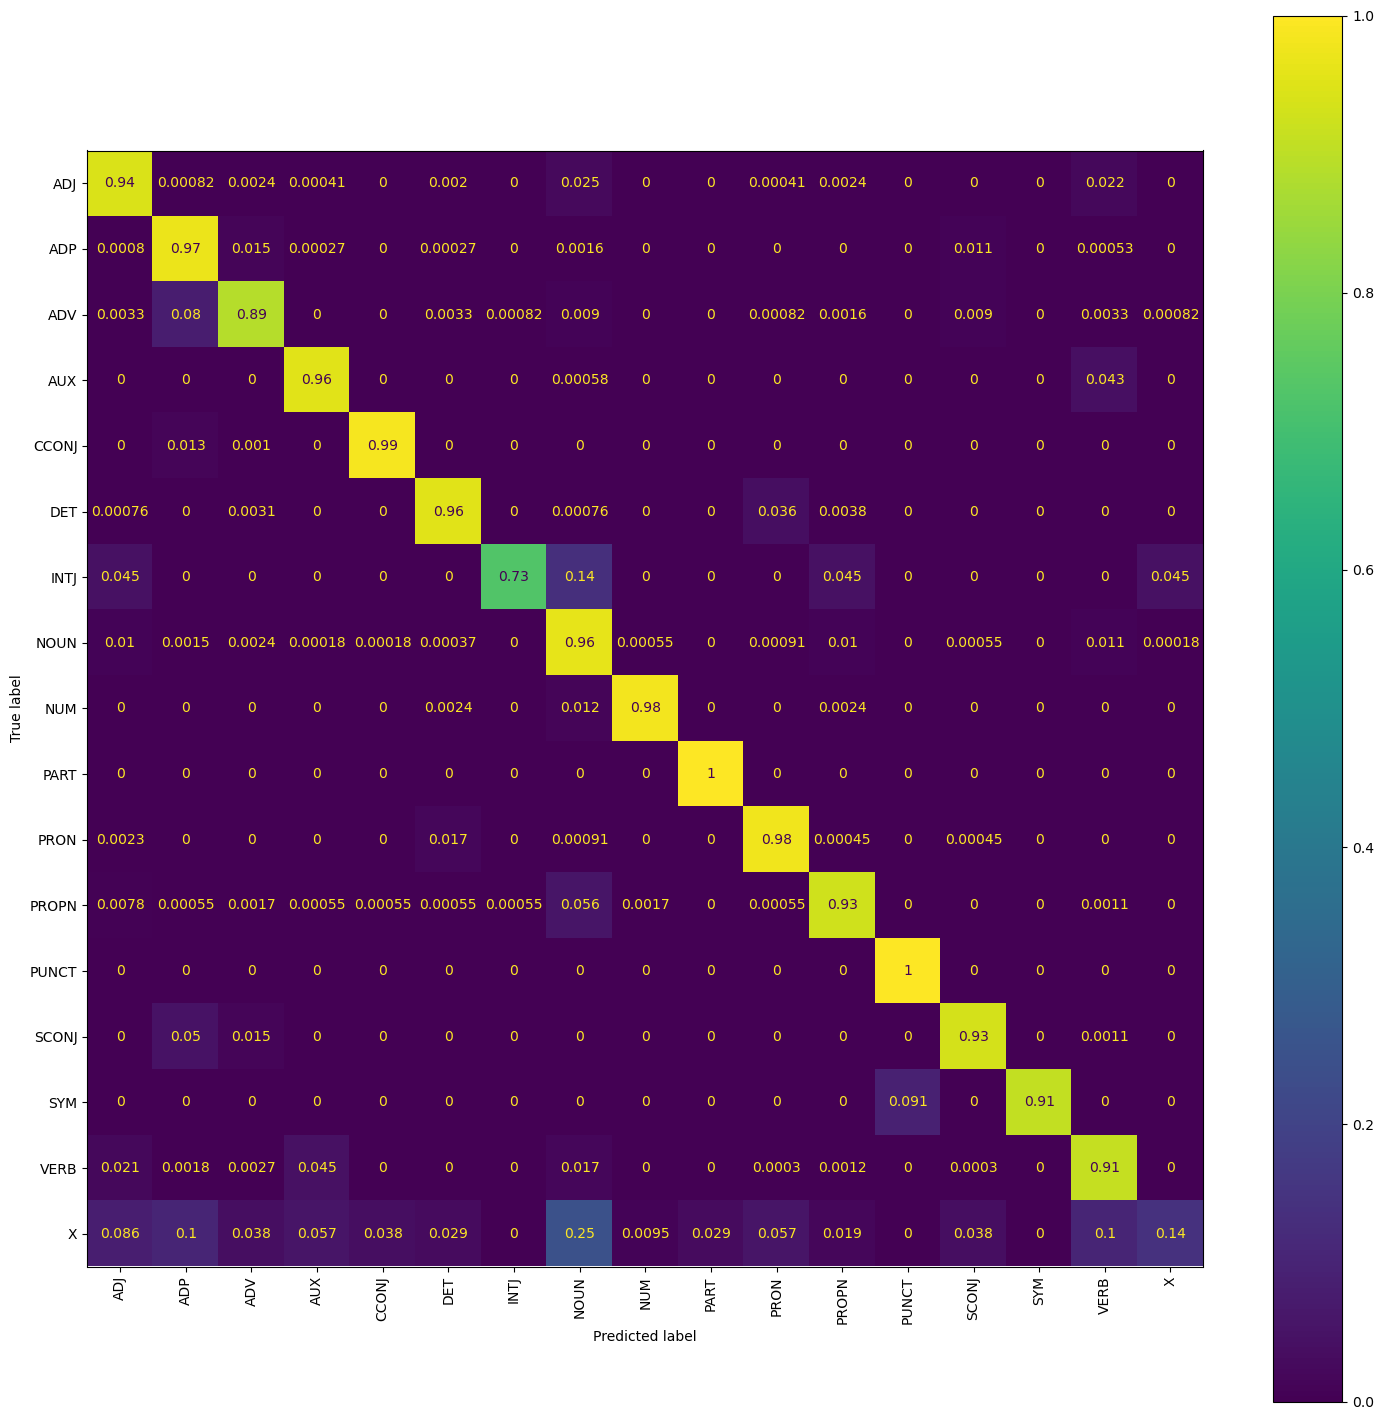

In [54]:
from sklearn.metrics import ConfusionMatrixDisplay
from matplotlib import pyplot as plt

flattend_dataset_Y_true = [tag for sent in test_data_y for tag in sent]
flattend_dataset_Y_pred = [tag for sent in predicted_test_data_y for tag in sent]
labels = sorted(set(flattend_dataset_Y_true))

fig, ax = plt.subplots(figsize=(18, 18))
disp = ConfusionMatrixDisplay.from_predictions(flattend_dataset_Y_true, flattend_dataset_Y_pred, labels=labels, normalize='true', xticks_rotation="vertical", ax=ax)
plt.show()


## Part 2 – Span identification with sequence models

In this part, you'll use the same sequence models for a different task: named entity recognition for English.

**Task 2.1** (0.5 point): Write the code to load the train and test data.

In [55]:
def load_ner_data(filename):
    # IMPLEMENT THE CODE TO LOAD THE NER DATA
    with open(filename, 'r', encoding='utf-8') as f:
        sentences_set = []
        labels_set = []
        text = f.read()
        # Sentences are separated by blank lines
        sentence_blocks = text.split("\n\n")

        for block in sentence_blocks:
            lines = block.strip().split('\n')
            words_list = []
            labels_list = []
            for line in lines:
                line = line.strip()

                # Skip empty lines and document separators
                if line == "" or line.startswith("-DOCSTART-"):
                    continue
                if len(line.split()) < 2:
                    continue

                # First column is the word, last column is the NER tag
                parts = line.split()
                word, label = parts[0], parts[-1]
                words_list.append(word)
                labels_list.append(label)

            # Skip blocks that only contained a document separator
            if words_list:
                sentences_set.append(words_list)
                labels_set.append(labels_list)

    return sentences_set, labels_set


train_nerdata_x, train_nerdata_y = load_ner_data('ner-train.txt')
test_nerdata_x, test_nerdata_y = load_ner_data('ner-test.txt')

In [56]:
train_nerdata_x[0], train_nerdata_y[0]

(['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.'],
 ['B-ORG', 'O', 'B-MISC', 'O', 'O', 'O', 'B-MISC', 'O', 'O'])

**Task 2.2** (0.5 point): Train a greedy tagger with the NER training data. Use any feature set that worked well for POS tagging, but *do not include transition features* for now. Compute the token-level accuracy of the test set, as before.

In [61]:
gt = GreedyTagger(additive_features)
gt.fit(train_nerdata_x, train_nerdata_y)

In [62]:
predicted_test_nerdata_y = gt.predict(test_nerdata_x)
tagging_accuracy(test_nerdata_y, predicted_test_nerdata_y)

0.9568213631958652

--------------------
### My explanation

In the first attemp, the model could achieve about 95.7% accuracy on NER test dataset.

--------------------

**Task 2.3** (1 point): Token-level accuracy is not well adapted to span identification tasks (why?). Instead, we want to compute precision, recall and f-score of the *entities*. Adapt the code below:

In [63]:
def get_ranges(l):
    """
    Helper procedure for eval_ner.
    You're not expected to change anything here.
    """
    elements = []
    current_element = None
    current_start = None
    for i, ll in enumerate(l):
        if ll == "O":
            if current_element != None:
                elements.append((current_element, current_start, i))
            current_element = None
            current_start = -1
        elif ll[0] == "B":
            if current_element != None:
                elements.append((current_element, current_start, i))
            current_element = ll[2:]
            current_start = i
        elif ll[0] == "I":
            if current_element != ll[2:]:
                elements.append((current_element, current_start, i))
                current_element = ll[2:]
                current_start = i
    return elements


def eval_ner(sys_labels, gold_labels):
    """
    Computes precision, recall and f1-score, using get_ranges() to identify the named entities.
    """
    tp, fp, fn = 0, 0, 0
    for sys_l, gold_l in zip(sys_labels, gold_labels):
        sys_ranges = get_ranges(sys_l)
        gold_ranges = get_ranges(gold_l)
        for r in sys_ranges:
            if r in gold_ranges:
                tp += 1
        ## TODO: also count fp and fn
            if r not in gold_ranges:
                fp += 1

        for r in gold_ranges:
            if r not in sys_ranges:
                fn += 1

    recall = 0
    prec = 0
    f1score = 0
    ## TODO: compute recall, precision and f1-score from tp, fp and fn
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    prec = tp / (tp + fp) if (tp + fp) > 0 else 0
    f1score = 2 * (prec * recall) / (prec + recall) if (prec + recall) > 0 else 0

    return recall, prec, f1score

Report precision, recall and f1-score of the model trained above.

In [64]:
recall, precision, f1score = eval_ner(predicted_test_nerdata_y, test_nerdata_y)
print(f"Recall: {recall:.4f}, Precision: {precision:.4f}, F1-score: {f1score:.4f}")

Recall: 0.7731, Precision: 0.6968, F1-score: 0.7330


--------------------
### My explanation

Accuracy doesn't always give us a good intuition about the model performance. In NER, the majority of tokens have the O tag, which means they are outside of any entity (about 84% of the tokens in the training data). In this situation, if the model predicts just O for every token, it will achieve about 84% accuracy even though it doesn't find any entity at all. That's why our model gets 95.7% accuracy, while the entity-level scores are much lower.

The other problem is that NER is a span identification task: an entity can contain several tokens (for example "Peter Blackburn" is B-PER I-PER), and it is only correct if its start, its end and its type are all correct. Token-level accuracy gives credit to each token separately, so if the model predicts only part of an entity correctly, it still gets points for those tokens, while at the entity level it is simply a wrong entity. Therefore, we evaluate the entities instead of the tokens.

As you can see based on the above scores, recall is better than precision. It's about 77%, which shows that among all of the true entities in the test set, 77% of them were found with the correct span and type. For precision the situation is worse, and it is about 70%, which shows that among all of the entities that the model predicted, 70% of them are correct.

Since recall is higher than precision, the model is not conservative: it finds most of the entities, but it also predicts many wrong ones. One reason could be that without history, the model doesn't know the previous tag, so it can produce broken or mixed spans, and each of them is counted as a wrong entity.

F1 score is the harmonic mean of precision and recall, and it is about 73%. It gives one number that balances both metrics.


--------------------

**Task 2.4** (1 point): Train a new model with transition features and predict the development set labels using `predict_with_history`. How does this change affect the token-level (accuracy) and entity-level (recall, precision, f1-score) metrics?

In [58]:
# I used additive_features function to train the model instead of trnasition_features because it's extented form of 
# transition_features and it has more features that can help the model to learn better.
gt = GreedyTagger(transition_features)
gt.fit(train_nerdata_x, train_nerdata_y)

/fp/homes01/u01/ec-armans/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [59]:
predicted_test_nerdata_y = gt.predict_with_history(test_nerdata_x)
tagging_accuracy(test_nerdata_y, predicted_test_nerdata_y)

0.9199526219446538

In [60]:
recall, precision, f1score = eval_ner(predicted_test_nerdata_y, test_nerdata_y)
print(f"Recall: {recall:.4f}, Precision: {precision:.4f}, F1-score: {f1score:.4f}")

Recall: 0.5557, Precision: 0.8584, F1-score: 0.6747


--------------------
### My explanation

Ok, now the situation is different. With transition features and history, precision increased a lot (from 70% to 86%), but recall dropped significantly (from 77% to 56%). Accuracy and F1-score also decreased, going from 95.7% and 73% to 92% and 67%, respectively. It should be mentioned that the model in Task 2.2 used additive_features, while this model uses transition_features, which doesn't have the prefix/suffix and capitalization features.


--------------------

**Task 2.5** (2 points): Take some 50 sentences from the test set and display the words, gold tags, and the predicted tags of the two systems. Can you identify error patterns that are typical for the two systems respectively?

In [69]:
# Here we have two systems, one with history and one without history. We can compare their performance on 50 random sentences from the test set.
gt_with_history = GreedyTagger(transition_features)
gt_with_history.fit(train_nerdata_x, train_nerdata_y)
predicted_with_history = gt_with_history.predict_with_history(test_nerdata_x)

gt_without_history = GreedyTagger(additive_features)
gt_without_history.fit(train_nerdata_x, train_nerdata_y)
predicted_without_history = gt_without_history.predict(test_nerdata_x)

/fp/homes01/u01/ec-armans/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [72]:
sum(p1 != p2 for s1, s2 in zip(predicted_with_history, predicted_without_history) for p1, p2 in zip(s1, s2))

3486

In [70]:
import pandas as pd

# Keep only sentences where at least one of the systems makes an error
error_idx = [i for i in range(len(test_nerdata_y)) if predicted_with_history[i] != test_nerdata_y[i] or predicted_without_history[i] != test_nerdata_y[i]]

rng = np.random.default_rng(42)
idx = rng.choice(error_idx, 50, replace=False)

sentence_ids = [i for i in idx for _ in test_nerdata_x[i]]
tokens = [token for sentence in [test_nerdata_x[i] for i in idx] for token in sentence]
labels = [label for labels in [test_nerdata_y[i] for i in idx] for label in labels]

flat_with_history = [label for labels in [predicted_with_history[i] for i in idx] for label in labels]
flat_without_history = [label for labels in [predicted_without_history[i] for i in idx] for label in labels]

display_df = pd.DataFrame({
    'Sentence': sentence_ids,
    'Token': tokens,
    'True Label': labels,
    'Predicted Label (with history)': flat_with_history,
    'Predicted Label (without history)': flat_without_history
})

# Here error columns are added to the display_df DataFrame to indicate whether the predicted labels match the true labels for each token.
# If the predicted label does not match the true label, the corresponding error column will contain "X"; otherwise, it will be empty.
display_df['error (with history)'] = display_df.apply(lambda row: "X" if row['True Label'] != row['Predicted Label (with history)'] else "", axis=1)
display_df['error (without history)'] = display_df.apply(lambda row: "X" if row['True Label'] != row['Predicted Label (without history)'] else "", axis=1)


In [71]:
# In the above code I considered 50 sentences which include at least one error in the predicted labels of either system. 
# But here I show just 10 sentences for brevity. The sentences are displayed in the order they appear in the test set.
for n, (sent_id, sent_df) in enumerate(display_df.groupby('Sentence', sort=True)):
    if n >= 10:
        break
    print(f"Sentence {sent_id}")
    display(sent_df.drop(columns='Sentence').reset_index(drop=True))

Sentence 218


,Token,True Label,Predicted Label (with history),Predicted Label (without history),error (with history),error (without history)
0,League,O,O,O,,
1,title-holders,O,O,O,,
2,Steaua,B-ORG,O,B-ORG,X,
3,Bucharest,I-ORG,O,I-ORG,X,
4,",",O,O,O,,
5,who,O,O,O,,
6,finished,O,O,O,,
7,bottom,O,O,O,,
8,of,O,O,O,,
9,their,O,O,O,,


Sentence 234


,Token,True Label,Predicted Label (with history),Predicted Label (without history),error (with history),error (without history)
0,MELBOURNE,B-LOC,O,B-LOC,X,
1,1996-12-06,O,O,O,,


Sentence 295


...

,Token,True Label,Predicted Label (with history),Predicted Label (without history),error (with history),error (without history)
0,Utrecht,B-ORG,O,B-ORG,X,
1,18,O,O,O,,
2,4,O,O,O,,
3,10,O,O,O,,
4,4,O,O,O,,
5,26,O,O,O,,
6,24,O,O,O,,
7,22,O,O,O,,


Sentence 673


,Token,True Label,Predicted Label (with history),Predicted Label (without history),error (with history),error (without history)
0,Bochum,B-ORG,B-ORG,B-ORG,,
1,2,O,O,O,,
2,(,O,O,O,,
3,Stickroth,B-PER,B-PER,B-PER,,
4,30th,O,O,O,,
5,pen,O,O,O,,
6,",",O,O,O,,
7,Wosz,B-PER,O,B-PER,X,
8,89th,O,O,O,,
9,),O,O,O,,


Sentence 740


,Token,True Label,Predicted Label (with history),Predicted Label (without history),error (with history),error (without history)
0,Amor,B-PER,O,O,X,X


--------------------
### My explanation

One thing: mentioning "with and without history" may be a little confusing. Without history, I used the additive_features function, which contains more features, and with history, I used the transition_features function. Essentially, in the following, we are comparing classifiers containing additive_features (without history) and transition_features (with history).


**Without history**: finds most entities, but produces broken or mixed spans (B-LOC I-ORG, B-MISC O I-MISC) and some wrong guesses (Faulk as ORG, TD as MISC).

**With history**: misses many entities (predicts O for names like Lara, HOBART, Utrecht), but when it finds one, the span is consistent; a wrong tag then propagates to the next tokens (Kirsten 18th as B-PER I-PER).

**Both**: errors on all-caps headlines (WEST INDIES) and on some rare names (Amor).


--------------------

## Part 3: Text classification with feed-forward neural networks

For this part, we go back to the text classification task used in the first assignment: language identification of Bokmål and Nynorsk.

Instead of manually creating a bag-of-subwords matrix with the BPE-encoded data, we go a simpler route this time and use the `CountVectorizer` class provided by Scikit-Learn. Have a look at the documentation of `CountVectorizer` here: https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction

With the default parameters, `CountVectorizer` will tokenize the data at whitespaces, remove punctuation signs and convert everything to lowercase. You can play around with the parameters if you wish, but the default settings work decently well. A useful thing to make the vectors smaller is to remove hapaxes, i.e. words that occur only once in the training data. You can achieve this with `min_df=2`.

**Task 3.1** (2 points): Write the code to produce `train_X, train_Y, test_X, test_Y`. Each `*_X` variable should contain a list of vectors produced by `CountVectorizer`. Each `*_Y` variable should contain a list of integers (1 for Nynorsk and 0 for Bokmål).

In [2]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(min_df=2)

In [3]:
import numpy as np

# First, we need to load the data from the NDT files. 
# The following function reads the sentences and their corresponding labels from a given file.
def load_ndt_data(filename):
    with open(filename, 'r', encoding='utf-8') as file_:
        lines = file_.readlines()
        sentences = [line.split('\t')[0].strip() for line in lines if line.strip()]
        labels = [1 if line.split('\t')[1].strip() == 'nno' else 0 for line in lines if line.strip()]
    return sentences, labels


train_X, train_Y = load_ndt_data('ndt_train_class.txt')
test_X, test_Y = load_ndt_data('ndt_test_class.txt')

vectorizer.fit(train_X)

train_X_vectorized = vectorizer.transform(train_X)
test_X_vectorized = vectorizer.transform(test_X)

train_Y = np.array(train_Y)
test_Y = np.array(test_Y)


**Task 3.2** (1 point): Create a logistic regression classifier, train it on the training set, and predict the labels of the test set. Compute accuracy, precision and recall, as in the previous assignment. How do your results compare with the previous assignment?

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

log_reg = LogisticRegression()
log_reg.fit(train_X_vectorized, train_Y)

LogisticRegression()

In [5]:
predictions = log_reg.predict(test_X_vectorized)
accuracy = accuracy_score(test_Y, predictions)
precision = precision_score(test_Y, predictions)
recall = recall_score(test_Y, predictions)
f1 = f1_score(test_Y, predictions)
print(f"Accuracy: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}, F1-score: {f1:.4f}")

Accuracy: 0.9434, Precision: 0.9702, Recall: 0.9074, F1-score: 0.9378


--------------------
### My explanation

| Metric | First Assignment | Second Assignment | Change |
| --- | --- | --- | --- |
| **Accuracy** | 93.84% | 94.34% | +0.50% |
| **Precision** | 95.13% | 97.02% | +1.89% |
| **Recall** | 91.59% | 90.74% | -0.85% |
| **F1-score** | 93.33% | 93.78% | +0.45% |

The second assignment shows a slight overall improvement, but reveals a classic precision-recall trade-off:

* **Precision improved (+1.89%):** The second model is better at ensuring its positive predictions are actually correct, resulting in fewer false positives.
* **Recall dropped (-0.85%):** The second model misses slightly more actual positive cases, resulting in more false negatives.
* **Overall gains (+0.50% Accuracy, +0.45% F1):** Despite the drop in recall, the combined metrics indicate the second model performs slightly better overall.

--------------------

**Task 3.3** (1 point): Let us use a simple feed-forward neural network classifier instead of logistic regression, but keep the input feature representation identical. Scikit-Learn provides a simple feed-forward classifier under the name `MLPClassifier`. The most important parameter is `hidden_layer_sizes`, which specifies the number and size of hidden layers. For example, `MLPClassifier(hidden_layer_sizes=(10, 5))` creates a classifier with two hidden layers, the first one with 10 neurons and the second one with 5 neurons. To start, keep the model simple and choose a single hidden layer with 10 neurons. How does this model perform in comparison with logistic regression?

In [8]:
from sklearn.neural_network import MLPClassifier

mlp_classifier = MLPClassifier(hidden_layer_sizes=(10,), max_iter=300, random_state=42)
mlp_classifier.fit(train_X_vectorized, train_Y)

MLPClassifier(hidden_layer_sizes=(10,), max_iter=300, random_state=42)

In [9]:
mlp_predictions = mlp_classifier.predict(test_X_vectorized)
mlp_accuracy = accuracy_score(test_Y, mlp_predictions)
mlp_precision = precision_score(test_Y, mlp_predictions)
mlp_recall = recall_score(test_Y, mlp_predictions)
mlp_f1 = f1_score(test_Y, mlp_predictions)
print(f"MLP Classifier - Accuracy: {mlp_accuracy:.4f}, Precision: {mlp_precision:.4f}, Recall: {mlp_recall:.4f}, F1-score: {mlp_f1:.4f}")

MLP Classifier - Accuracy: 0.9282, Precision: 0.9409, Recall: 0.9041, F1-score: 0.9221


--------------------
### My explanation

| Metric | Logistic Regression | MLP | Change |
| --- | --- | --- | --- |
| **Accuracy** | 94.34% | 92.82% | -1.52% |
| **Precision** | 97.02% | 94.09% | -2.93% |
| **Recall** | 90.74% | 90.41% | -0.33% |
| **F1-score** | 93.78% | 92.21% | -1.57% |

**Performance Analysis**

The MLP model shows a clear degradation in performance compared to Logistic Regression. There is no precision-recall trade-off here; the MLP performs worse across all measured metrics:

* **Precision dropped (-2.93%):** The MLP is worse at ensuring its positive predictions are correct, resulting in more false positives.
* **Recall dropped (-0.33%):** The MLP also misses slightly more actual positive cases, resulting in more false negatives.
* **Overall decline (-1.52% Accuracy, -1.57% F1):** With decreases in both accuracy and the F1-score, the Logistic Regression model comprehensively outperformed the MLP on this task.

Here, it can be said that we are witnessing **overfitting** when using an MLP.

--------------------

**Task 3.4** (1 point): Try to improve the results by adding more and/or larger hidden layers. You're not expected to work with more than 50 neurons in total, as this slows down the training process drastically.

In [10]:
# So, lets try more complex model with more hidden layers to see if it can improve the performance of the model. 
mlp_classifier = MLPClassifier(hidden_layer_sizes=(20,10,5), max_iter=300, random_state=42)
mlp_classifier.fit(train_X_vectorized, train_Y)

MLPClassifier(hidden_layer_sizes=(20, 10, 5), max_iter=300, random_state=42)

In [11]:
mlp_predictions = mlp_classifier.predict(test_X_vectorized)
mlp_accuracy = accuracy_score(test_Y, mlp_predictions)
mlp_precision = precision_score(test_Y, mlp_predictions)
mlp_recall = recall_score(test_Y, mlp_predictions)
mlp_f1 = f1_score(test_Y, mlp_predictions)
print(f"MLP Classifier - Accuracy: {mlp_accuracy:.4f}, Precision: {mlp_precision:.4f}, Recall: {mlp_recall:.4f}, F1-score: {mlp_f1:.4f}")

MLP Classifier - Accuracy: 0.9221, Precision: 0.9363, Recall: 0.8953, F1-score: 0.9153


| Metric | Simple MLP `(10,)` | Complex MLP `(20, 10, 5)` | Change |
| --- | --- | --- | --- |
| **Accuracy** | 92.82% | 92.21% | -0.61% |
| **Precision** | 94.09% | 93.63% | -0.46% |
| **Recall** | 90.41% | 89.53% | -0.88% |
| **F1-score** | 92.21% | 91.53% | -0.68% |

**Performance Analysis**

Adding complexity to the network degraded the performance across every single metric.

* **Overfitting:** Because we are using vectorized text data (`train_X_vectorized`), our input space is likely highly dimensional and sparse. A deeper network with three hidden layers has significantly more parameters, making it prone to memorizing noise in the training data (overfitting) rather than learning generalizable patterns.
* **Simpler is better for this data:** Our results confirm a clear trend for this specific dataset: lower capacity models perform better. The single-layer MLP outperformed the deep MLP, and our earlier Logistic Regression (which effectively acts as a network with zero hidden layers) outperformed both.

Now, let us see if we can improve the input representation. Instead of a bag-of-words model created with `CountVectorizer`, we will obtain document embeddings from a pretrained Norwegian SentenceBert model (in particular, the [base model from the National Library of Norway](https://huggingface.co/NbAiLab/nb-sbert-base)). The following snippet shows how to load and use such a model.

In [15]:
from sentence_transformers import SentenceTransformer

# Uncomment the corresponding line:

# model = SentenceTransformer('NbAiLab/nb-sbert-base') # if you use your own environment

model = SentenceTransformer("NbAiLab/nb-sbert-base", cache_folder="/fp/homes01/u01/ec-armans/hf_models") # if you use Fox

sentences = [
    "This is a Norwegian boy",
    "Dette er en norsk gutt",
    "Dette er ein norsk gut",
]
embeddings = model.encode(sentences)
print(embeddings)

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/9.83k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/853 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

[[ 1.4281036   0.3951879   0.06262595 ...  1.1759274   0.5969337
  -0.12693615]
 [ 1.4975812  -0.5266647  -0.03449126 ...  1.3204105   0.85494727
   0.14108095]
 [ 1.5804617  -0.11839715 -0.08846294 ...  1.2216046   0.9193565
   0.16344163]]


**Task 3.5** (1 point): Produce embeddings for the training and test sets and train a new `MLPClassifier` with these embeddings as input features. Can you further improve the evaluation scores?

Note: Producing the embeddings and training the model will take longer than in previous exercises, around 10 minutes.

In [19]:
train_X_embeddings = model.encode(train_X)
test_X_embeddings = model.encode(test_X)

In [20]:
mlp_classifier = MLPClassifier(hidden_layer_sizes=(10), max_iter=300, random_state=42)
mlp_classifier.fit(train_X_embeddings, train_Y)

MLPClassifier(hidden_layer_sizes=10, max_iter=300, random_state=42)

In [21]:
mlp_predictions = mlp_classifier.predict(test_X_embeddings)
mlp_accuracy = accuracy_score(test_Y, mlp_predictions)
mlp_precision = precision_score(test_Y, mlp_predictions)
mlp_recall = recall_score(test_Y, mlp_predictions)
mlp_f1 = f1_score(test_Y, mlp_predictions)
print(f"MLP Classifier - Accuracy: {mlp_accuracy:.4f}, Precision: {mlp_precision:.4f}, Recall: {mlp_recall:.4f}, F1-score: {mlp_f1:.4f}")

MLP Classifier - Accuracy: 0.9489, Precision: 0.9509, Recall: 0.9399, F1-score: 0.9454


| Metric | Simple MLP (Vectorized Text) | Simple MLP (SBERT Embeddings) | Change |
| --- | --- | --- | --- |
| **Accuracy** | 92.82% | 94.89% | +2.07% |
| **Precision** | 94.09% | 95.09% | +1.00% |
| **Recall** | 90.41% | 93.99% | +3.58% |
| **F1-score** | 92.21% | 94.54% | +2.33% |

**Performance Analysis**

This is a massive breakthrough. By upgrading our feature extraction from sparse word counts (vectorized text) to dense semantic embeddings (`NbAiLab/nb-sbert-base`), we solved the performance bottleneck.

* **The Power of Dense Embeddings:** Our previous vectorized data created highly dimensional, sparse inputs that the MLP struggled with. SBERT provides dense, context-aware vectors specifically trained on Norwegian text. Neural networks like MLPs thrive on this type of continuous, dense data.
* **Massive Recall Boost (+3.58%):** The semantic understanding from the embeddings allowed our model to identify far more actual positive cases that the word-matching vectorizer missed.
* **Our New Best Model:** Not only did this completely fix the MLP's previous poor performance, but it also beat our baseline Logistic Regression in Accuracy (94.89% vs 94.34%) and F1-score (94.54% vs 93.78%). By changing the *quality of our data* rather than just adding layers, we achieved our best results yet.